# Complete PDAC atlas

This tutorial jointly models all 108 Visium sections from 39 patients in
[GSE282302](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE282302).
We identify tumor and microenvironment programs and compare their spatial
overlap across sections. Download the original count matrices and spatial
coordinates from the [GEO data record](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE282302)
and combine them in an AnnData object saved as
`data/pdac/pdac_atlas_counts.h5ad` under the tutorial repository root.

Store counts in `adata.X`, gene symbols in `var_names` and coordinates in
`obsm['spatial']`. In `obs`, use `sample_id` for section identifiers;
`sample_name` can store the corresponding GEO names. The displayed examples use
section identifiers 0–107 from the paper's reference atlas. Match genes to a
common column order, keeping coordinates and metadata aligned by row.

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse

import sort

## 1. Load and preprocess the atlas

Load the count atlas with its section identifiers.

In [3]:
adata = sc.read_h5ad(Path("../data/pdac/pdac_atlas_counts.h5ad"))
adata

AnnData object with n_obs × n_vars = 353257 × 19144
    obs: 'sample_id', 'array_row', 'array_col', 'in_tissue'
    obsm: 'spatial'

Filter locations and genes, normalize library sizes, log-transform the
expression matrix and select 10,000 batch-aware highly variable genes.

In [4]:
detected_per_location = np.asarray((adata.X > 0).sum(axis=1)).ravel()
adata = adata[detected_per_location >= 200].copy()

min_cells = max(3, int(adata.n_obs * 0.01))
detected_per_gene = np.asarray((adata.X > 0).sum(axis=0)).ravel()
mean_per_gene = np.asarray(adata.X.mean(axis=0)).ravel()
adata = adata[:, (detected_per_gene >= min_cells) & (mean_per_gene >= 0.01)].copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=10_000,
    batch_key="sample_id",
    flavor="seurat_v3",
    subset=False,
)
hvg_mask = adata.var["highly_variable"].to_numpy().copy()
hvg_index = np.flatnonzero(hvg_mask)
hvg_cells = np.asarray((adata[:, hvg_mask].X > 0).sum(axis=0)).ravel()
hvg_means = np.asarray(adata[:, hvg_mask].X.mean(axis=0)).ravel()
problematic_hvg = (
    (hvg_means < 0)
    | (hvg_means < -0.5)
    | (hvg_cells < max(5, int(adata.n_obs * 0.01)))
)
hvg_mask[hvg_index[problematic_hvg]] = False
adata = adata[:, hvg_mask].copy()
adata.X = sparse.csr_matrix(adata.X, dtype=np.float32)
adata

scanpy/preprocessing/_highly_variable_genes.py:64: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  warnings.warn(


AnnData object with n_obs × n_vars = 352102 × 10000
    obs: 'sample_id', 'array_row', 'array_col', 'in_tissue'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'log1p', 'hvg'
    obsm: 'spatial'

## 2. Build the spatial graph and fit SORT

Build a 24-neighbour graph within each section to supply the spatial
relationships used by SORT. The combined graph follows the expression row order.

In [5]:
sort.build_per_sample_graph(
    adata, n_neighbors=24, sample_key="sample_id"
)

Building spatial graphs for 108 samples (k=24)...


  [10/108] Processed


  [20/108] Processed


  [30/108] Processed


  [40/108] Processed


...

  [90/108] Processed


  [100/108] Processed


  [108/108] Processed


✓ Combined Laplacian: (352102, 352102), 8,802,310 non-zeros



AnnData object with n_obs × n_vars = 352102 × 10000
    obs: 'sample_id', 'array_row', 'array_col', 'in_tissue'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'log1p', 'hvg', 'spatial_laplacian'
    obsm: 'spatial'

Next, fit the 40-component PDAC model, comprising one background and 39 signal
components, using the package defaults for regularization and optimization.

In [6]:
result = sort.fit(
    adata,
    n_components=40,
    use_highly_variable=False,
)
result

SORT: 352,102 locations x 10,000 genes; 40 components; device=cuda


Initializing activities and profiles...


  ⚠️  Insufficient GPU memory (free=25.09 GB, need≈42.25 GB). Falling back to CPU numpy for HALS.


Stage 1: orthogonal Procrustes updates (50 epochs)


  Stage 1: 10/50 epochs


...

  Stage 2: 80/100 epochs


  Stage 2: 90/100 epochs


  Stage 2: 100/100 epochs


Finished in 1758.5 s
Stored .obsm['X_sort'] (352102, 40) and .varm['sort_signatures'] (10000, 40)


SORTResult(W=(352102, 40) spots_x_components, Q=(10000, 40) genes_x_components, background_component=0, fit_time=1758.5s)

## 3. Inspect and select programs

Start with the ten genes with the largest positive weights in each signal
profile. These genes describe the program's gene composition. Combine them
with the gene associations and spatial maps below to identify programs of
interest.

In [7]:
top_positive_genes = pd.DataFrame([
    {
        "GEP": f"GEP{k:02d}",
        "Top positive genes": ", ".join(
            pd.Series(result.Q[:, k], index=result.gene_names)
            .loc[lambda weights: weights > 0].nlargest(10).index
        ),
    }
    for k in range(1, result.Q.shape[1])
]).set_index("GEP")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(top_positive_genes)

,Top positive genes
GEP,
GEP01,"KRT17, LCN2, LAMC2, TRIM29, MMP11, KLK6, KRT16, CLDN4, KRT7, KRT8"
GEP02,"PNLIP, CELA3A, PRSS1, CPA1, CLPS, CPB1, CTRC, CEL, AMY2A, REG1A"
GEP03,"C7, CCN1, C3, FOS, CCDC80, EGR1, FBLN1, CCN2, SELENOP, PTGDS"
GEP04,"COL1A1, SPARC, POSTN, COL5A1, COL1A2, COL3A1, FN1, ACTA2, SFRP2, VCAN"
GEP05,"UBD, IDO1, HLA-A, IFI6, IGHG1, WARS, IGLV3-1, S100A14, PLAAT4, C3"
GEP06,"IGHG1, IGLC2, IGKV1D-12, IGLC3, IGHV3-30, IGKC, IGLC1, IGHA1, IGHG2, IGHV3-35"
GEP07,"DES, ACTG2, MYH11, SYNM, CNN1, TPM2, MYLK, SYNPO2, GREM1, TPM1"
GEP08,"TFF1, CEACAM6, LGALS4, GPX2, CTSE, TFF3, TSPAN8, MUC1, MUC5AC, SPINK1"
GEP09,"SERF1A, COL1A2, COL3A1, COL1A1, UBC, TMSB10, ACTG1, TPM2, S100A6, FN1"


Choose the components and sections to visualize in the configuration below.
The defaults use the example's component indices; update them for your fit.
Indices refer directly to columns of `result.W` and `result.Q`, with the
background component at index 0. The spatial maps help refine your selection.

In [8]:
programs = {"classical": 8, "basal": 16}
display_geps = [
    2, 30, 29, programs["classical"], 1, programs["basal"],
    21, 32, 28, 4, 15, 14, 20, 11,
]
sections = ["68", "10"]
assert all(0 < gep < result.W.shape[1] for gep in display_geps + list(programs.values()))

## 4. Examine gene associations

Relate the recovered activities to representative PDAC and microenvironment
genes using conditional gene–GEP coefficients, which account for the other
fitted activities and provide gene-level evidence for annotation.
Standardize each gene's coefficients across all signal programs, then display
the selected programs to highlight their relative gene associations.

In [9]:
signature_genes = {
    "Acinar": ["CTRB1", "REG1B", "CLPS", "AMY2A"],
    "Tumor exocrine": ["CTRB2", "REG3A", "CELA3A", "PRSS2"],
    "Ductal": ["SLC4A4", "SERPINA5", "CFTR", "SORBS2"],
    "Tumor classical": ["LGALS4", "AGR2", "TOX3", "ST6GALNAC1", "GPX2", "CEACAM6", "TSPAN8", "TFF1", "FXYD3", "TFF3"],
    "Tumor basal": ["FAM83A", "CST6", "KRT7", "SCEL", "TNS4", "S100A2", "KRT6A", "KRT17", "ANXA8L1", "SLC2A1"],
    "Hypoxia": ["NDRG1", "ENO1", "LDHA", "ALDOA", "SERPINE1", "MAFF", "TES", "PFKFB3", "NFIL3", "BTG1"],
    "Proliferative": ["TOP2A", "MCM2", "HELLS", "TACC3"],
    "Activated stroma": ["THBS2", "FN1", "COL5A2", "CTHRC1"],
    "myCAF": ["POSTN", "TPM1", "ACTA2", "TAGLN"],
    "iCAF": ["CFD", "CXCL12", "CXCL8", "HAS1"],
    "Endothelial": ["CD93", "HYAL2", "SPRY1", "CD34"],
    "Macrophage": ["C1QB", "CTSS", "C1QA", "C1QC"],
    "T cell": ["CD3D", "PTPRC", "IL7R", "CD3E"],
    "B cell": ["CD37", "LTB", "CXCR4", "CD53"],
}
genes = [gene for module in signature_genes.values() for gene in module]
gene_index = adata.var_names.get_indexer(genes)
if np.any(gene_index < 0):
    raise ValueError(f"Missing display genes: {np.asarray(genes)[gene_index < 0].tolist()}")

association = sort.compute_posthoc_b(
    adata.X[:, gene_index],
    result.W[:, 1:],
    gene_names=genes,
    component_names=[f"GEP{i:02d}" for i in range(1, result.W.shape[1])],
    return_stats=False,
)
z = (association.B - association.B.mean(axis=1, keepdims=True)) / association.B.std(axis=1, keepdims=True)
heatmap = np.clip(z[:, np.asarray(display_geps) - 1].T, -2, 2)

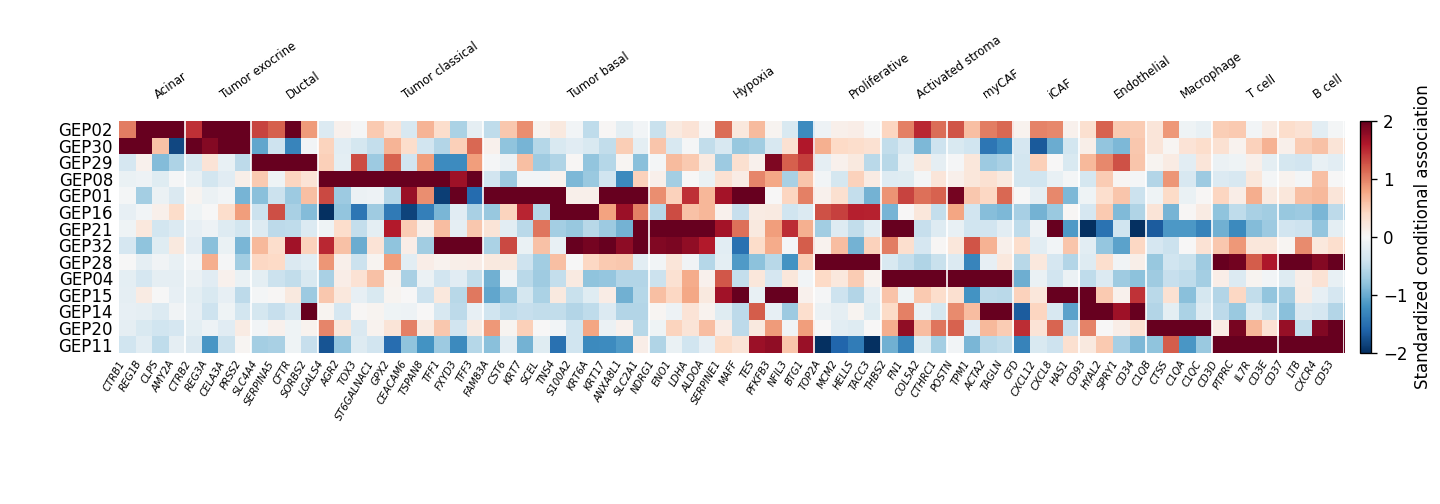

In [10]:
fig, ax = plt.subplots(figsize=(12.0, 4.2))
image = ax.imshow(heatmap, cmap="RdBu_r", vmin=-2, vmax=2, aspect="equal")
ax.set_yticks(np.arange(len(display_geps)), [f"GEP{i:02d}" for i in display_geps])
ax.set_xticks(np.arange(len(genes)), genes, rotation=60, ha="right", fontsize=6, fontstyle="italic")

offset = 0
for label, module in signature_genes.items():
    center = offset + (len(module) - 1) / 2
    ax.text(center, -1.7, label, rotation=35, ha="left", va="bottom", fontsize=7)
    offset += len(module)
    ax.axvline(offset - 0.5, color="white", linewidth=1.0)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(image, ax=ax, fraction=0.018, pad=0.012,
             label="Standardized conditional association")
fig.subplots_adjust(left=0.08, right=0.96, bottom=0.30, top=0.76)
plt.show()

## 5. Compare spatial overlap across sections

Compare the selected classical- and basal-associated programs across the two
sections. The first two columns show their activities; the third distinguishes
locations in the top 20% for either program or both within each section.

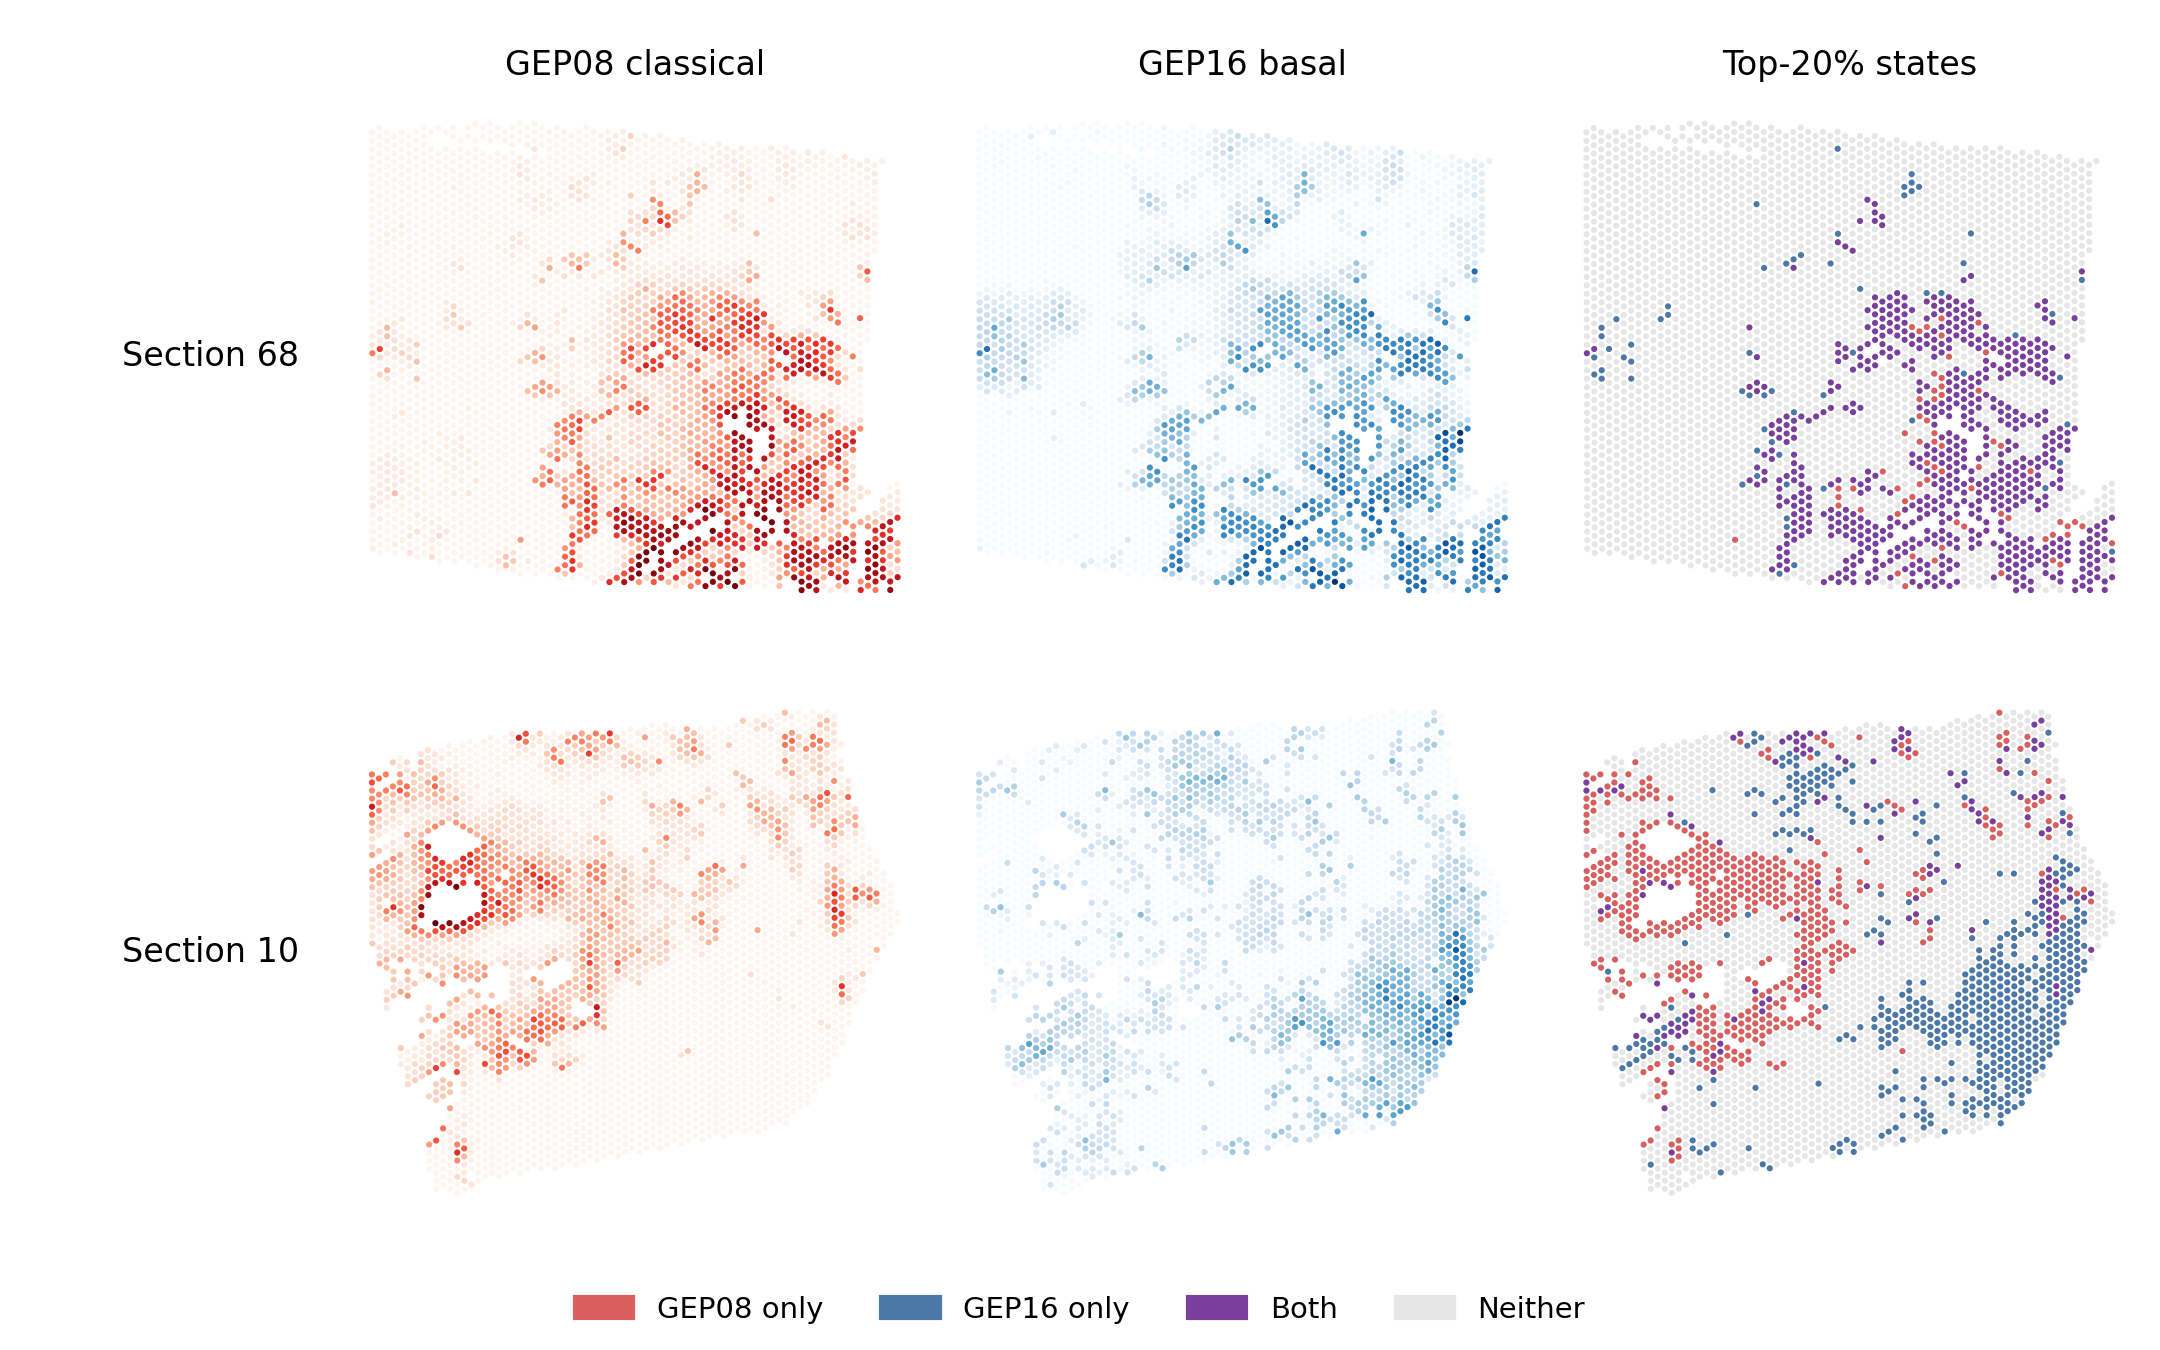

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.5))
for row, section in enumerate(sections):
    mask = adata.obs["sample_id"].astype(str).to_numpy() == section
    xy = np.asarray(adata.obsm["spatial"])[mask]
    first = result.W[mask, programs["classical"]]
    second = result.W[mask, programs["basal"]]
    first_cut = np.quantile(first, 0.80)
    second_cut = np.quantile(second, 0.80)
    first_high = first >= first_cut
    second_high = second >= second_cut
    for column, (values, cmap, label) in enumerate((
        (first, "Reds", f"GEP{programs['classical']:02d} classical"),
        (second, "Blues", f"GEP{programs['basal']:02d} basal"),
    )):
        axes[row, column].scatter(xy[:, 0], xy[:, 1], c=values, s=2.2,
                                  cmap=cmap, linewidths=0, rasterized=True)
        axes[row, column].set_title(label if row == 0 else "", fontsize=8)
    states = np.full(mask.sum(), "#E6E6E6", dtype=object)
    states[first_high & ~second_high] = "#D95F5F"
    states[~first_high & second_high] = "#4C78A8"
    states[first_high & second_high] = "#7A3E9D"
    axes[row, 2].scatter(xy[:, 0], xy[:, 1], c=states, s=2.2,
                         linewidths=0, rasterized=True)
    axes[row, 2].set_title("Top-20% states" if row == 0 else "", fontsize=8)
    axes[row, 0].text(-0.08, 0.5, f"Section {section}",
                      transform=axes[row, 0].transAxes,
                      ha="right", va="center", fontsize=8)
    for ax in axes[row]:
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.axis("off")
fig.subplots_adjust(left=0.16, right=0.99, bottom=0.02, top=0.94,
                    wspace=0.05, hspace=0.08)
fig.legend(
    handles=[
        Patch(color="#D95F5F", label=f"GEP{programs['classical']:02d} only"),
        Patch(color="#4C78A8", label=f"GEP{programs['basal']:02d} only"),
        Patch(color="#7A3E9D", label="Both"),
        Patch(color="#E6E6E6", label="Neither"),
    ],
    loc="lower center", ncol=4, frameon=False, fontsize=7,
)
fig.subplots_adjust(bottom=0.09)
plt.show()